# Sales Data Analysis: D2C E-commerce (2024-2025)

End-to-end analysis of **12,000+ order records** for an Indian D2C apparel-accessories brand: data cleaning, KPI calculation, trend analysis and dashboard visuals.

> Dataset is synthetic but modelled on realistic D2C patterns (festive seasonality, repeat buyers, channel mix). Generate it with `python src/generate_data.py`.

In [1]:
import sys, pandas as pd
sys.path.append('../src')
import matplotlib.pyplot as plt
from clean_data import clean
from analyze_sales import compute_kpis, revenue_share, CHARTS
%matplotlib inline
pd.set_option('display.float_format', '{:,.2f}'.format)

## 1. Load raw data and inspect quality issues

In [2]:
raw = pd.read_csv('../data/raw/sales_raw.csv')
print(raw.shape)
raw.head()

(12150, 15)


,order_id,order_date,customer_id,region,state,channel,payment_method,category,product_name,unit_price,quantity,discount,sales,profit,order_status
0,ORD109129,2024-11-24,CUST01492,West,Goa,Website,Credit Card,Gift Sets,Luxury Gift Box (4 Pairs),1999,4,0.25,"5,997.00","1,742.43",Delivered
1,ORD104525,2025-01-17,CUST03638,East,Odisha,Marketplace,Net Banking,Kids' Socks,Anti-Slip Toddler Socks,299,1,0.10,269.10,104.30,Delivered
2,ORD101744,2024-05-21,CUST01607,North,Haryana,Mobile App,Net Banking,Men's Socks,Classic Crew Socks,349,2,0.00,698.00,360.97,Delivered
3,ORD106247,2025-07-21,CUST00346,West,Maharashtra,Instagram Shop,Credit Card,Men's Socks,Merino Wool Dress Socks,799,0,0.05,759.05,420.08,Delivered
4,ORD107862,2024-02-13,CUST03578,West,Gujarat,Marketplace,COD,Accessories,Travel Laundry Pouch,249,1,0.05,236.55,92.90,Cancelled


In [3]:
quality = pd.DataFrame({
    'missing_values': raw.isna().sum(),
    'dtype': raw.dtypes.astype(str)})
print('Duplicate rows:', raw.duplicated().sum())
print('Invalid quantities (<=0):', (raw['quantity'] <= 0).sum())
print('Messy channel labels:', raw['channel'].unique())
quality[quality['missing_values'] > 0]

Duplicate rows: 150
Invalid quantities (<=0): 25
Messy channel labels: <StringArray>
[        'Website',     'Marketplace',      'Mobile App',  'Instagram Shop',
     'mobile app ',    'marketplace ', 'instagram shop ',        'website ']
Length: 8, dtype: str


,missing_values,dtype
region,91,str
payment_method,91,str


## 2. Clean and preprocess
Deduplicate, standardise text, impute region from state, drop invalid quantities, correct sales entry errors, engineer date features, keep delivered orders.

In [4]:
df, log = clean(raw)
df.head()

Cleaning summary
  raw_rows                      12,150
  duplicates_removed               150
  missing_region_filled             90
  missing_payment_filled            90
  invalid_quantity_removed          25
  sales_values_corrected            12
  cancelled_or_returned          1,053
  clean_rows                    10,922


,order_id,order_date,customer_id,region,state,channel,payment_method,category,product_name,unit_price,quantity,discount,sales,profit,order_status,year,month,quarter,weekday,profit_margin
0,ORD109129,2024-11-24,CUST01492,West,Goa,Website,Credit Card,Gift Sets,Luxury Gift Box (4 Pairs),1999,4,0.25,"5,997.00","1,742.43",Delivered,2024,2024-11,2024Q4,Sunday,0.29
1,ORD104525,2025-01-17,CUST03638,East,Odisha,Marketplace,Net Banking,Kids' Socks,Anti-Slip Toddler Socks,299,1,0.10,269.10,104.30,Delivered,2025,2025-01,2025Q1,Friday,0.39
2,ORD101744,2024-05-21,CUST01607,North,Haryana,Mobile App,Net Banking,Men's Socks,Classic Crew Socks,349,2,0.00,698.00,360.97,Delivered,2024,2024-05,2024Q2,Tuesday,0.52
3,ORD108410,2025-12-24,CUST02224,East,West Bengal,Marketplace,UPI,Men's Socks,Bamboo Formal Socks,599,2,0.00,"1,198.00",554.91,Delivered,2025,2025-12,2025Q4,Wednesday,0.46
4,ORD110124,2024-03-30,CUST03271,West,Madhya Pradesh,Website,UPI,Gift Sets,Festive Combo Pack,1499,2,0.15,"2,548.30",913.42,Delivered,2024,2024-03,2024Q1,Saturday,0.36


## 3. Headline KPIs

In [5]:
pd.Series(compute_kpis(df), name='value').to_frame()

,value
total_revenue,"13,243,951.50"
total_profit,"5,259,204.46"
profit_margin,0.40
orders,"10,922.00"
customers,"3,341.00"
avg_order_value,"1,212.59"
yoy_revenue_growth,0.27
repeat_customer_rate,0.64
festive_revenue_share,0.27


## 4. Revenue trend

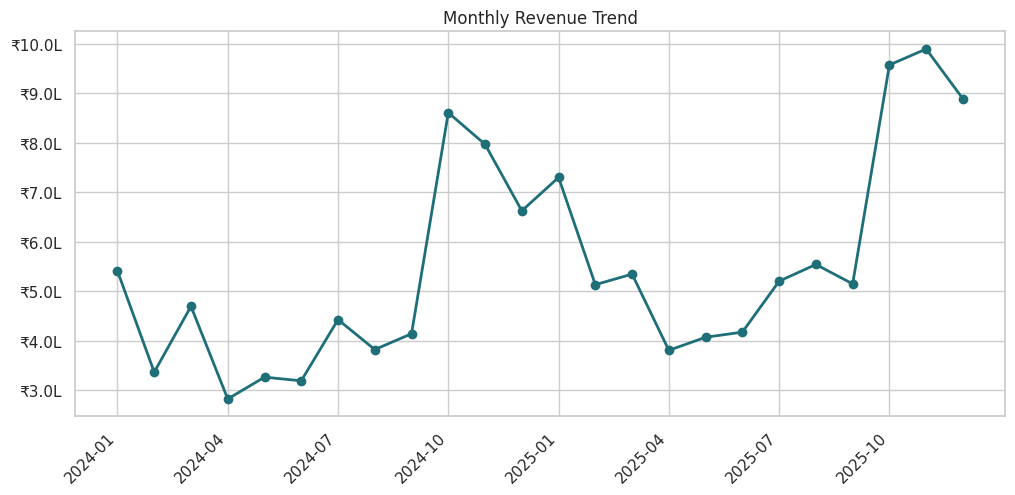

In [6]:
fig, ax = plt.subplots(figsize=(12,5)); CHARTS['01_monthly_revenue_trend'](df, ax); plt.show()

Revenue spikes every **October-November** (festive season) and grows year on year, so inventory and ad spend should ramp up from September.

## 5. Category, region and channel performance

In [7]:
revenue_share(df, 'category')

,revenue,profit,orders,share,margin
category,,,,,
Gift Sets,"4,253,371.60","1,761,932.16",1318,0.32,0.41
Men's Socks,"3,977,614.00","1,620,500.03",3852,0.30,0.41
Women's Socks,"3,532,913.10","1,288,007.67",3300,0.27,0.36
Kids' Socks,"941,617.90","398,832.76",1544,0.07,0.42
Accessories,"538,434.90","189,931.84",908,0.04,0.35


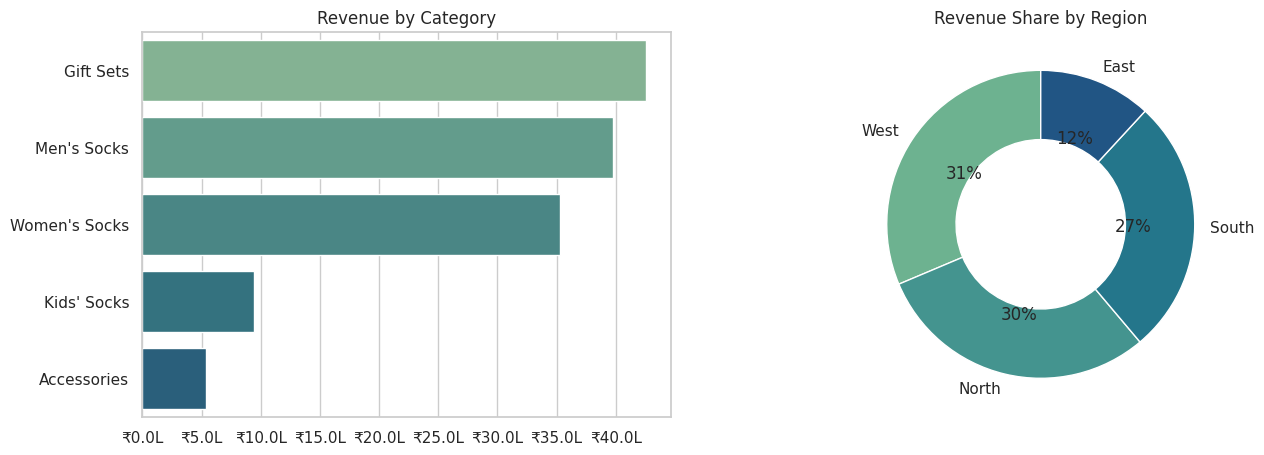

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15,5))
CHARTS['02_revenue_by_category'](df, axes[0]); CHARTS['03_revenue_by_region'](df, axes[1]); plt.show()

In [9]:
revenue_share(df, 'channel')

,revenue,profit,orders,share,margin
channel,,,,,
Website,"5,194,412.65","2,057,366.90",4193,0.39,0.40
Mobile App,"3,569,893.55","1,474,225.83",2938,0.27,0.41
Marketplace,"3,169,510.85","1,249,534.09",2685,0.24,0.39
Instagram Shop,"1,310,134.45","478,077.64",1106,0.10,0.36


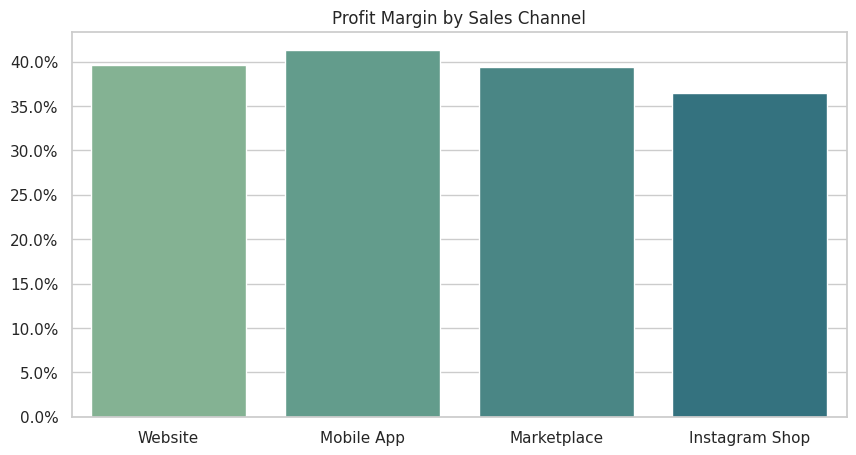

In [10]:
fig, ax = plt.subplots(figsize=(10,5)); CHARTS['04_margin_by_channel'](df, ax); plt.show()

## 6. When do customers buy?

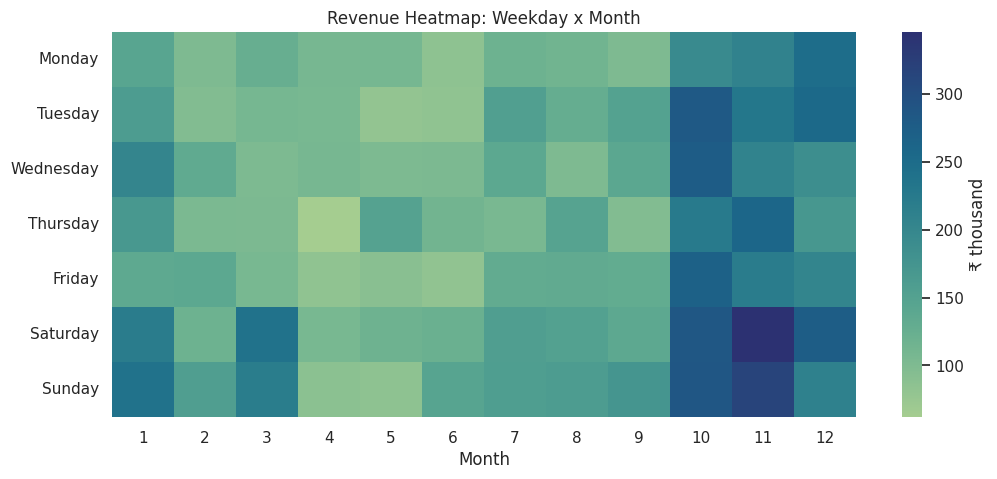

In [11]:
fig, ax = plt.subplots(figsize=(12,5)); CHARTS['05_weekday_month_heatmap'](df, ax); plt.show()

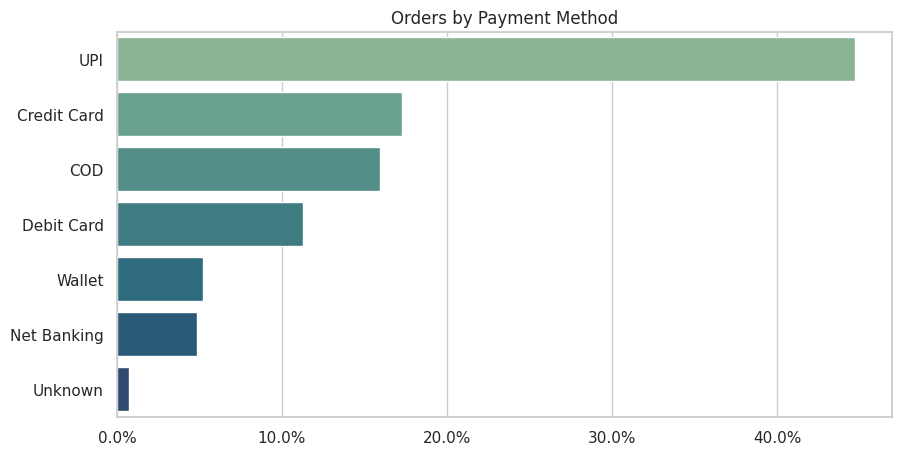

In [12]:
fig, ax = plt.subplots(figsize=(10,5)); CHARTS['06_payment_methods'](df, ax); plt.show()

## 7. Customer behaviour

In [13]:
orders_per_cust = df.groupby('customer_id')['order_id'].nunique()
top10 = df.groupby('customer_id')['sales'].sum().sort_values(ascending=False)
print(f"Repeat customer rate: {(orders_per_cust > 1).mean():.1%}")
print(f"Top 20% of customers contribute {top10.head(int(len(top10)*0.2)).sum()/top10.sum():.1%} of revenue")
orders_per_cust.describe()

Repeat customer rate: 64.4%
Top 20% of customers contribute 61.4% of revenue


count   3,341.00
mean        3.27
std         8.97
min         1.00
25%         1.00
50%         2.00
75%         3.00
max       397.00
Name: order_id, dtype: float64

## 8. Key insights & recommendations
1. **Festive season drives ~27% of annual revenue** in just two months: plan stock and campaigns from September.
2. **Gift Sets are the #1 revenue category** despite few orders (highest AOV): bundle and upsell them on product pages.
3. **Website + Mobile App deliver ~66% of revenue** with stronger margins than marketplaces: invest in owned channels.
4. **Instagram Shop has the lowest margin**: review discounting there.
5. **UPI dominates payments; COD is ~16%**: prepaid incentives can cut COD cancellation risk.
6. **Revenue is concentrated in top customers**: a loyalty programme for repeat buyers is a high-ROI lever (see the Customer Segmentation project).